<a href="https://colab.research.google.com/github/2anoFIAP/AED-KPOP-CP-DATASCIENCE/blob/main/AEDTeste.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:

# =====================================================
# BLOCO 1 — CONFIGURAÇÃO DO AMBIENTE
# =====================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

# Configuração dos gráficos
sns.set_theme(style="whitegrid", context="notebook")

plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["figure.dpi"] = 110

# Configurações de exibição do pandas
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:,.2f}".format)

SEED = 42

print("Ambiente configurado com sucesso!")
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)


Ambiente configurado com sucesso!
Pandas: 2.2.3
Seaborn: 0.13.2


In [5]:

# =====================================================
# BLOCO 2 — GERAÇÃO DO DATASET SINTÉTICO
# =====================================================

rng = np.random.default_rng(SEED)

linhas = []

frete_base = {
    "Sudeste": 12,
    "Sul": 17,
    "Nordeste": 29,
    "Centro-Oeste": 22,
    "Norte": 38
}

id_pedido = 1

# Simular 4.000 clientes
for cliente_id in range(1, 4001):

    regiao = str(rng.choice(list(frete_base.keys())))

    # Perfis de utilização de cupons
    perfil_cupom = float(rng.choice([0.1, 0.5, 0.9]))

    primeira_compra = (
        pd.Timestamp("2025-01-01")
        + pd.Timedelta(days=int(rng.integers(0, 211)))
    )

    # Pelo menos uma compra inicial
    dias = [0]

    if rng.random() < 0.65:
        dias.append(int(rng.integers(1, 30)))

    # Simular recompras nos 90 dias seguintes
    media_recompras = (
        1.5 if perfil_cupom < 0.9 else 0.9
    )

    qtd_futura = int(rng.poisson(media_recompras))

    dias.extend(
        rng.integers(30, 120, size=qtd_futura).tolist()
    )

    for dia in dias:

        modalidade = str(rng.choice(
            ["ultra", "rapida", "normal"],
            p=[0.30, 0.40, 0.30]
        ))

        prazo = {
            "ultra": int(rng.integers(1, 3)),
            "rapida": int(rng.integers(3, 6)),
            "normal": int(rng.integers(6, 10))
        }[modalidade]

        receita = round(
            float(rng.gamma(4, 60) + 30), 2
        )

        cupom = bool(rng.random() < perfil_cupom)

        desconto = round(
            receita * float(rng.uniform(0.08, 0.25))
            if cupom else 0,
            2
        )

        custo_produto = round(
            receita * float(rng.uniform(0.47, 0.68)),
            2
        )

        adicional_logistico = {
            "ultra": 20,
            "rapida": 9,
            "normal": 0
        }[modalidade]

        custo_logistico = round(
            frete_base[regiao]
            + adicional_logistico
            + float(rng.uniform(0, 8)),
            2
        )

        nota_base = {
            "ultra": 4.6,
            "rapida": 4.5,
            "normal": 3.95
        }[modalidade]

        avaliacao = round(
            float(
                np.clip(
                    rng.normal(nota_base, 0.5),
                    1, 5
                )
            ),
            1
        )

        linhas.append({
            "pedido_id": id_pedido,
            "cliente_id": cliente_id,
            "data_pedido": (
                primeira_compra
                + pd.Timedelta(days=int(dia))
            ),
            "regiao": regiao,
            "receita_bruta": receita,
            "desconto_valor": desconto,
            "custo_produto": custo_produto,
            "custo_logistico": custo_logistico,
            "prazo_entrega_dias": prazo,
            "avaliacao_cliente": avaliacao,
            "cupom_aplicado": cupom
        })

        id_pedido += 1

# Criar DataFrame
df = pd.DataFrame(linhas)

# Introduzir dados ausentes de forma controlada
df["cupom_aplicado"] = df["cupom_aplicado"].astype(object)

ausencias = {
    "avaliacao_cliente": 0.04,
    "custo_logistico": 0.01,
    "cupom_aplicado": 0.01,
    "regiao": 0.005
}

for coluna, proporcao in ausencias.items():
    indices = rng.choice(
        df.index,
        size=int(len(df) * proporcao),
        replace=False
    )

    df.loc[indices, coluna] = np.nan

# Data de encerramento da observação
DATA_CORTE = pd.Timestamp("2025-12-31")

# Salvar arquivo CSV
df.to_csv("ecommerce_sintetico.csv", index=False)

print("=" * 55)
print("DATASET SINTÉTICO CRIADO")
print("=" * 55)

print("Total de pedidos:", len(df))
print("Total de clientes:", df["cliente_id"].nunique())
print("Total de regiões:", df["regiao"].nunique())
print("Data inicial:", df["data_pedido"].min())
print("Data final dos pedidos:", df["data_pedido"].max())
print("Data de corte:", DATA_CORTE.date())

display(df.head(10))


DATASET SINTÉTICO CRIADO
Total de pedidos: 11767
Total de clientes: 4000
Total de regiões: 5
Data inicial: 2025-01-01 00:00:00
Data final dos pedidos: 2025-11-24 00:00:00
Data de corte: 2025-12-31


,pedido_id,cliente_id,data_pedido,regiao,receita_bruta,desconto_valor,custo_produto,custo_logistico,prazo_entrega_dias,avaliacao_cliente,cupom_aplicado
0,1,1,2025-05-19,Sudeste,248.08,58.93,150.14,18.58,8,4.20,True
1,2,1,2025-07-27,Sudeste,157.20,32.84,85.59,39.77,2,4.50,True
2,3,2,2025-06-10,Centro-Oeste,206.53,33.01,105.29,43.04,2,4.20,True
3,4,2,2025-06-16,Centro-Oeste,346.92,46.18,223.69,48.44,2,4.70,True
4,5,3,2025-02-20,Norte,121.46,0.00,71.59,59.12,2,5.00,False
5,6,3,2025-03-12,Norte,107.76,0.00,63.17,51.47,4,4.90,False
6,7,4,2025-03-15,Centro-Oeste,204.47,0.00,113.55,48.51,2,4.30,False
7,8,4,2025-03-28,Centro-Oeste,139.22,0.00,80.08,43.22,2,4.80,False
8,9,4,2025-06-26,Centro-Oeste,240.97,24.11,161.93,38.27,4,4.00,True
9,10,4,2025-04-19,Centro-Oeste,211.55,0.00,111.52,42.77,1,4.40,False


In [6]:

# =====================================================
# BLOCO 3 — LIMPEZA E ENGENHARIA DE ATRIBUTOS
# =====================================================

# 1. Validar a unidade de análise: um pedido por linha

if df["pedido_id"].isna().any():
    raise ValueError("Existem pedidos sem ID.")

if df["pedido_id"].duplicated().any():
    raise ValueError("Existem pedidos duplicados.")

# 2. Converter colunas para os tipos adequados

colunas_numericas = [
    "receita_bruta",
    "desconto_valor",
    "custo_produto",
    "custo_logistico",
    "prazo_entrega_dias",
    "avaliacao_cliente"
]

for coluna in colunas_numericas:
    df[coluna] = pd.to_numeric(
        df[coluna],
        errors="coerce"
    )

df["data_pedido"] = pd.to_datetime(
    df["data_pedido"], errors="coerce"
)

df["regiao"] = (
    df["regiao"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

mapa_cupom = {
    "true": True,
    "false": False,
    "1": True,
    "0": False,
    "sim": True,
    "nao": False,
    "não": False,
    "yes": True,
    "no": False
}

df["cupom_aplicado"] = (
    df["cupom_aplicado"]
    .astype("string")
    .str.strip()
    .str.lower()
    .map(mapa_cupom)
    .astype("boolean")
)

# 3. Auditoria de valores ausentes

qualidade = pd.DataFrame({
    "ausentes": df.isna().sum(),
    "percentual": df.isna().mean() * 100
}).sort_values("percentual", ascending=False)

print("AUDITORIA DE VALORES AUSENTES")
display(qualidade)

# 4. Validar dados financeiros

financeiras = [
    "receita_bruta",
    "desconto_valor",
    "custo_produto",
    "custo_logistico"
]

df["financeiro_ok"] = (
    df[financeiras].notna().all(axis=1)
    & df["receita_bruta"].gt(0)
    & df["desconto_valor"].between(
        0, df["receita_bruta"]
    )
    & df["custo_produto"].ge(0)
    & df["custo_logistico"].ge(0)
)

# 5. Receita líquida

df["receita_liquida"] = (
    df["receita_bruta"] - df["desconto_valor"]
).where(df["financeiro_ok"])

# 6. Contribuição antes da logística

df["contrib_antes_logistica"] = (
    df["receita_liquida"] -
    df["custo_produto"]
).where(df["financeiro_ok"])

# 7. Contribuição efetiva por pedido

df["contribuicao"] = (
    df["contrib_antes_logistica"] -
    df["custo_logistico"]
).where(df["financeiro_ok"])

# 8. Peso logístico na receita líquida

df["taxa_logistica"] = (
    df["custo_logistico"] /
    df["receita_liquida"].replace(0, np.nan)
).where(df["financeiro_ok"])

# 9. Avaliações válidas

df["nota_valida"] = (
    df["avaliacao_cliente"]
    .where(df["avaliacao_cliente"].between(1, 5))
)

# 10. Prazos válidos

df["prazo_valido"] = (
    df["prazo_entrega_dias"]
    .where(df["prazo_entrega_dias"].ge(0))
)

# 11. Resumo da qualidade

print("\nRESUMO DA QUALIDADE")
print("Pedidos totais:", len(df))

print(
    "Pedidos financeiros válidos:",
    int(df["financeiro_ok"].sum())
)

print(
    "Pedidos financeiros inválidos/incompletos:",
    int((~df["financeiro_ok"]).sum())
)

print(
    "Avaliações válidas:",
    int(df["nota_valida"].count())
)

# 12. Margem global ponderada

base_financeira = df[df["financeiro_ok"]]

receita_total = base_financeira["receita_liquida"].sum()
contrib_total = base_financeira["contribuicao"].sum()

margem_global = (
    100 * contrib_total / receita_total
    if receita_total > 0 else np.nan
)

print(
    f"Margem global de contribuição: {margem_global:.2f}%"
)

display(df.head())


AUDITORIA DE VALORES AUSENTES


,ausentes,percentual
avaliacao_cliente,470,3.99
custo_logistico,117,0.99
cupom_aplicado,117,0.99
regiao,58,0.49
data_pedido,0,0.00
pedido_id,0,0.00
cliente_id,0,0.00
custo_produto,0,0.00
desconto_valor,0,0.00
receita_bruta,0,0.00



RESUMO DA QUALIDADE
Pedidos totais: 11767
Pedidos financeiros válidos: 11650
Pedidos financeiros inválidos/incompletos: 117
Avaliações válidas: 11297
Margem global de contribuição: 22.69%


,pedido_id,cliente_id,data_pedido,regiao,receita_bruta,desconto_valor,custo_produto,custo_logistico,prazo_entrega_dias,avaliacao_cliente,cupom_aplicado,financeiro_ok,receita_liquida,contrib_antes_logistica,contribuicao,taxa_logistica,nota_valida,prazo_valido
0,1,1,2025-05-19,Sudeste,248.08,58.93,150.14,18.58,8,4.20,True,True,189.15,39.01,20.43,0.10,4.20,8
1,2,1,2025-07-27,Sudeste,157.20,32.84,85.59,39.77,2,4.50,True,True,124.36,38.77,-1.00,0.32,4.50,2
2,3,2,2025-06-10,Centro-Oeste,206.53,33.01,105.29,43.04,2,4.20,True,True,173.52,68.23,25.19,0.25,4.20,2
3,4,2,2025-06-16,Centro-Oeste,346.92,46.18,223.69,48.44,2,4.70,True,True,300.74,77.05,28.61,0.16,4.70,2
4,5,3,2025-02-20,Norte,121.46,0.00,71.59,59.12,2,5.00,False,True,121.46,49.87,-9.25,0.49,5.00,2


INDICADORES FINANCEIROS REGIONAIS


,regiao,pedidos,receita,contrib_pre,contrib_pos,custo_log,margem_pre_pct,margem_pos_pct,logistica_pct,erosao_pp
2,Norte,2312,"573,104.96","217,386.03","97,950.93","119,435.10",37.93,17.09,20.84,20.84
1,Nordeste,2237,"565,560.30","211,033.25","115,877.15","95,156.10",37.31,20.49,16.83,16.83
0,Centro-Oeste,2423,"594,393.30","222,422.46","137,013.30","85,409.16",37.42,23.05,14.37,14.37
4,Sul,2379,"593,365.59","223,041.45","149,752.44","73,289.01",37.59,25.24,12.35,12.35
3,Sudeste,2241,"562,153.69","212,009.93","154,766.72","57,243.21",37.71,27.53,10.18,10.18


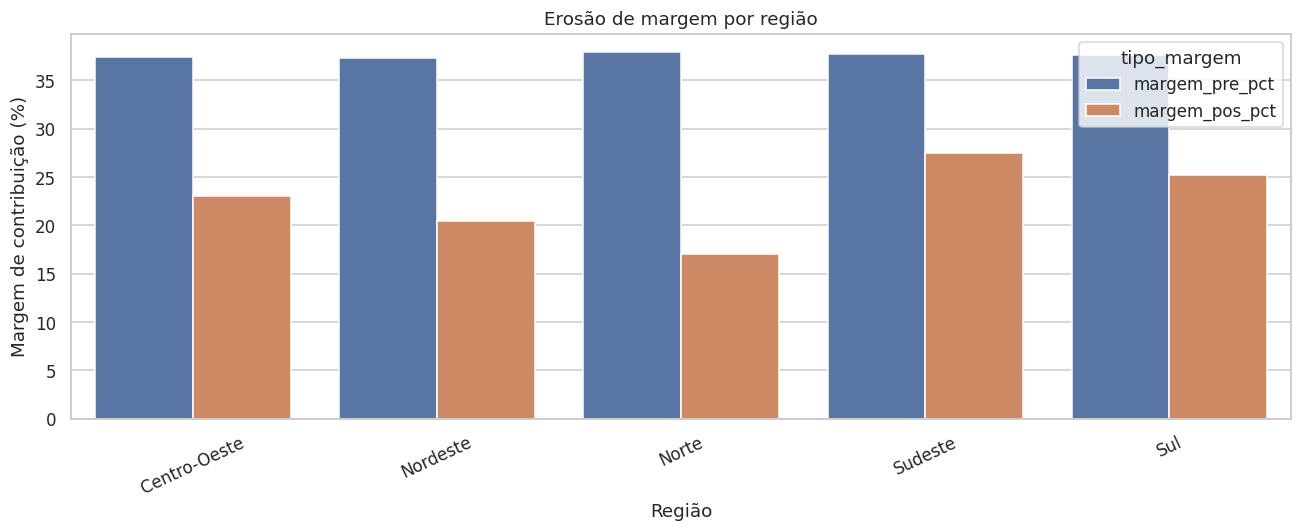


CRUZAMENTO: REGIÃO X PESO LOGÍSTICO


,regiao,faixa_logistica,pedidos,receita,contribuicao,margem_pct,margem_exibida
0,Centro-Oeste,até 5%,26,"14,946.22","5,495.13",36.77,NaN
1,Centro-Oeste,5–10%,494,"189,268.72","57,916.89",30.60,30.60
2,Centro-Oeste,10–20%,1149,"281,549.82","64,311.56",22.84,22.84
3,Centro-Oeste,>20%,754,"108,628.54","9,289.72",8.55,8.55
4,Nordeste,até 5%,10,"8,289.99","3,051.06",36.80,NaN
5,Nordeste,5–10%,242,"109,675.48","33,719.83",30.75,30.75
6,Nordeste,10–20%,1021,"292,304.51","67,257.10",23.01,23.01
7,Nordeste,>20%,964,"155,290.32","11,849.16",7.63,7.63
8,Norte,5–10%,87,"46,543.00","15,277.21",32.82,32.82
9,Norte,10–20%,869,"286,556.70","67,694.10",23.62,23.62


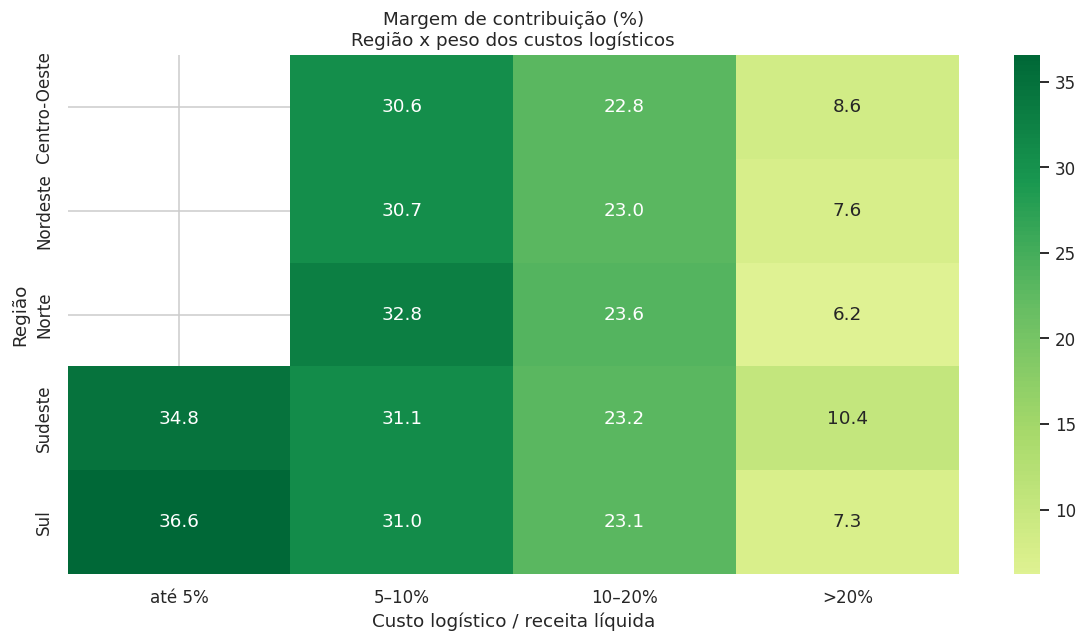


RESULTADO EXPLORATÓRIO
Maior erosão regional: Norte
Erosão em pontos percentuais: 20.84
Margem após logística: 17.09

AÇÃO CANDIDATA: testar otimização logística na região de maior erosão.
KPI: contribuição média por pedido elegível.


In [7]:

# =====================================================
# BLOCO 4 — INSIGHT 1: LOGÍSTICA E MARGEM
# =====================================================

base1 = df.loc[
    df["financeiro_ok"] &
    df["regiao"].notna()
].copy()

if base1.empty:
    raise ValueError("Não há pedidos válidos para análise.")

# 1. Agregação financeira por região

regional = (
    base1.groupby("regiao")
    .agg(
        pedidos=("pedido_id", "size"),
        receita=("receita_liquida", "sum"),
        contrib_pre=("contrib_antes_logistica", "sum"),
        contrib_pos=("contribuicao", "sum"),
        custo_log=("custo_logistico", "sum")
    )
    .reset_index()
)

regional["margem_pre_pct"] = (
    100 * regional["contrib_pre"] /
    regional["receita"].replace(0, np.nan)
)

regional["margem_pos_pct"] = (
    100 * regional["contrib_pos"] /
    regional["receita"].replace(0, np.nan)
)

regional["logistica_pct"] = (
    100 * regional["custo_log"] /
    regional["receita"].replace(0, np.nan)
)

regional["erosao_pp"] = (
    regional["margem_pre_pct"] -
    regional["margem_pos_pct"]
)

print("INDICADORES FINANCEIROS REGIONAIS")

display(
    regional.sort_values(
        "erosao_pp", ascending=False
    )
)

# 2. Comparação da margem antes e depois do frete

grafico1 = regional.melt(
    id_vars="regiao",
    value_vars=[
        "margem_pre_pct",
        "margem_pos_pct"
    ],
    var_name="tipo_margem",
    value_name="margem_pct"
)

plt.figure(figsize=(12, 5))

sns.barplot(
    data=grafico1,
    x="regiao",
    y="margem_pct",
    hue="tipo_margem"
)

plt.title("Erosão de margem por região")
plt.xlabel("Região")
plt.ylabel("Margem de contribuição (%)")
plt.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# 3. Criar faixas de intensidade logística

faixas_logisticas = [
    "até 5%",
    "5–10%",
    "10–20%",
    ">20%"
]

base1["faixa_logistica"] = pd.cut(
    base1["taxa_logistica"],
    bins=[-0.000001, 0.05, 0.10, 0.20, np.inf],
    labels=faixas_logisticas,
    include_lowest=True
)

# 4. Cruzamento entre região e faixa logística

cruzamento = (
    base1.dropna(subset=["faixa_logistica"])
    .groupby(
        ["regiao", "faixa_logistica"],
        observed=True
    )
    .agg(
        pedidos=("pedido_id", "size"),
        receita=("receita_liquida", "sum"),
        contribuicao=("contribuicao", "sum")
    )
    .reset_index()
)

cruzamento["margem_pct"] = (
    100 * cruzamento["contribuicao"] /
    cruzamento["receita"].replace(0, np.nan)
)

# Não interpretar células de amostra muito pequena
MIN_PEDIDOS = 30

cruzamento["margem_exibida"] = (
    cruzamento["margem_pct"].where(
        cruzamento["pedidos"] >= MIN_PEDIDOS
    )
)

matriz = cruzamento.pivot(
    index="regiao",
    columns="faixa_logistica",
    values="margem_exibida"
).reindex(columns=faixas_logisticas)

print("\nCRUZAMENTO: REGIÃO X PESO LOGÍSTICO")
display(cruzamento)

# 5. Heatmap

if matriz.notna().any().any():

    plt.figure(figsize=(11, 6))

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn",
        center=0
    )

    plt.title(
        "Margem de contribuição (%)\n"
        "Região x peso dos custos logísticos"
    )
    plt.xlabel("Custo logístico / receita líquida")
    plt.ylabel("Região")
    plt.tight_layout()
    plt.show()

# 6. Destaque analítico

pior_regiao = regional.sort_values(
    "erosao_pp", ascending=False
).iloc[0]

print("\nRESULTADO EXPLORATÓRIO")

print(
    "Maior erosão regional:",
    pior_regiao["regiao"]
)

print(
    "Erosão em pontos percentuais:",
    round(pior_regiao["erosao_pp"], 2)
)

print(
    "Margem após logística:",
    round(pior_regiao["margem_pos_pct"], 2)
)

print(
    "\nAÇÃO CANDIDATA: testar otimização "
    "logística na região de maior erosão."
)

print(
    "KPI: contribuição média por pedido elegível."
)


COORTES E FREQUÊNCIA DE CUPONS


,coorte,faixa_cupom,clientes,contrib_90_media,recompra_pct,pedidos_futuros_medios
0,2025-01,0%,244,91.44,72.54,1.38
1,2025-01,0–50%,111,65.51,67.57,1.23
2,2025-01,>50%,208,48.06,70.67,1.07
3,2025-02,0%,214,89.34,73.36,1.35
4,2025-02,0–50%,82,78.87,70.73,1.34
5,2025-02,>50%,204,42.84,67.65,1.08
6,2025-03,0%,223,99.05,78.03,1.51
7,2025-03,0–50%,104,91.66,71.15,1.38
8,2025-03,>50%,263,54.95,67.68,1.16
9,2025-04,0%,215,102.93,79.53,1.53


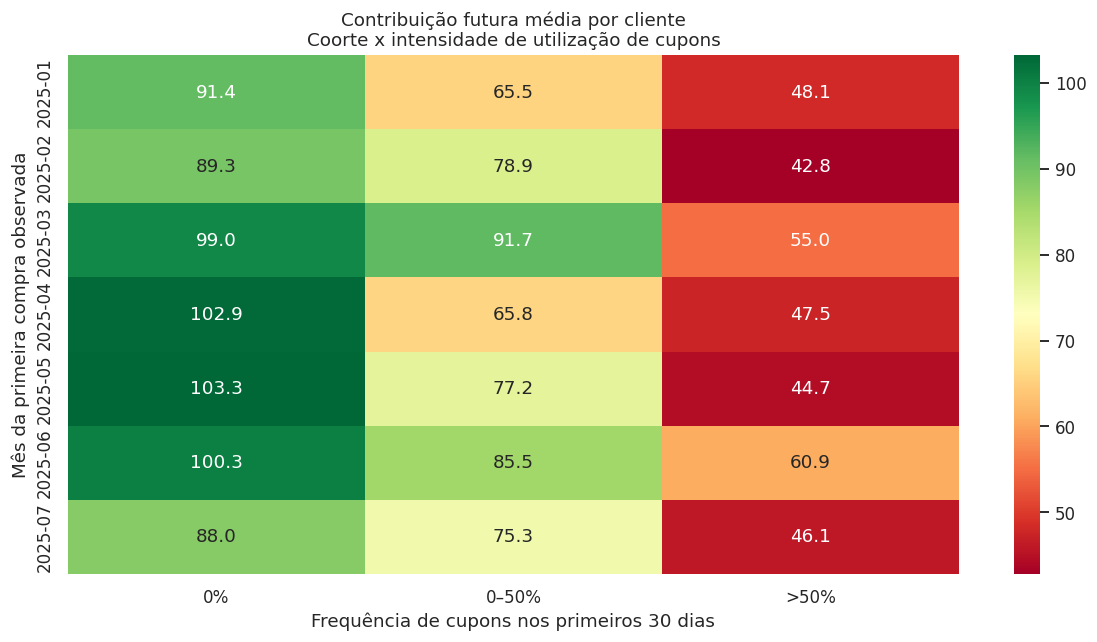


COMPARAÇÃO ENTRE SEGMENTOS
Diferença média entre coortes comparáveis: -47.04
Intervalo bootstrap descritivo de 95%: [-53.27 -40.32]

ANÁLISE DE SENSIBILIDADE


,clientes,contrib_media,recompra_pct
faixa_cupom,,,
0%,918,95.26,74.84
0–50%,722,77.06,70.91
>50%,906,47.38,64.13



KPI RECOMENDADO: contribuição média futura por cliente alocado em uma política de cupons.


In [8]:

# =====================================================
# BLOCO 5 — INSIGHT 2: CUPONS, COORTES E VALOR FUTURO
# =====================================================

# 1. Histórico válido de clientes

historico = df.dropna(
    subset=["cliente_id", "data_pedido"]
).copy()

primeiro = (
    historico.groupby("cliente_id")["data_pedido"]
    .min()
    .rename("primeira_compra")
)

historico = historico.join(
    primeiro,
    on="cliente_id"
)

historico["dia_relativo"] = (
    historico["data_pedido"] -
    historico["primeira_compra"]
).dt.days

# 2. Exposição aos cupons: dias 0 a 29

inicial = historico[
    historico["dia_relativo"].between(0, 29)
]

exposicao = (
    inicial.groupby("cliente_id")
    .agg(
        pedidos_30=("pedido_id", "size"),
        cupons_30=(
            "cupom_aplicado",
            lambda s: s.eq(True).sum()
        ),
        cupons_desconhecidos=(
            "cupom_aplicado",
            lambda s: s.isna().sum()
        )
    )
)

# 3. Resultado futuro: dias 30 a 119

posterior = historico[
    historico["dia_relativo"].between(30, 119)
]

resultado = (
    posterior.groupby("cliente_id")
    .agg(
        pedidos_90=("pedido_id", "size"),
        invalidos_90=(
            "financeiro_ok",
            lambda s: (~s).sum()
        ),
        contrib_90=(
            "contribuicao",
            lambda s: s.sum(min_count=1)
        )
    )
)

# 4. Construir tabela por cliente

clientes = (
    primeiro.to_frame()
    .join(exposicao)
    .join(resultado)
)

clientes["pedidos_90"] = (
    clientes["pedidos_90"].fillna(0).astype(int)
)

clientes["invalidos_90"] = (
    clientes["invalidos_90"].fillna(0).astype(int)
)

# Sem recompra observada na janela completa:
# contribuição futura efetivamente igual a zero.
clientes.loc[
    clientes["pedidos_90"].eq(0),
    "contrib_90"
] = 0.0

# 5. Selecionar somente clientes com histórico completo

clientes = clientes.loc[
    (
        clientes["primeira_compra"]
        + pd.Timedelta(days=120)
        <= DATA_CORTE
    )
    & clientes["cupons_desconhecidos"].eq(0)
    & clientes["invalidos_90"].eq(0)
    & clientes["contrib_90"].notna()
].copy()

# 6. Calcular intensidade de cupons

clientes["freq_cupom_30"] = (
    clientes["cupons_30"] /
    clientes["pedidos_30"]
)

ordem_cupons = ["0%", "0–50%", ">50%"]

clientes["faixa_cupom"] = pd.cut(
    clientes["freq_cupom_30"],
    bins=[-0.001, 0, 0.5, 1],
    labels=ordem_cupons
)

clientes["coorte"] = (
    clientes["primeira_compra"]
    .dt.to_period("M")
    .astype(str)
)

clientes["recomprou_90"] = (
    clientes["pedidos_90"] > 0
).astype(int)

# 7. Indicadores por coorte e segmento

tabela2 = (
    clientes.groupby(
        ["coorte", "faixa_cupom"],
        observed=True
    )
    .agg(
        clientes=("contrib_90", "size"),
        contrib_90_media=("contrib_90", "mean"),
        recompra_pct=(
            "recomprou_90",
            lambda s: 100 * s.mean()
        ),
        pedidos_futuros_medios=(
            "pedidos_90", "mean"
        )
    )
    .reset_index()
)

print("COORTES E FREQUÊNCIA DE CUPONS")
display(tabela2)

# 8. Matrizes para o heatmap

valores = tabela2.pivot(
    index="coorte",
    columns="faixa_cupom",
    values="contrib_90_media"
).reindex(columns=ordem_cupons)

volumes = tabela2.pivot(
    index="coorte",
    columns="faixa_cupom",
    values="clientes"
).reindex(columns=ordem_cupons)

MIN_CLIENTES = 20

mapa2 = valores.where(
    volumes >= MIN_CLIENTES
)

# 9. Heatmap da contribuição futura

if mapa2.notna().any().any():

    plt.figure(figsize=(11, 6))

    sns.heatmap(
        mapa2,
        annot=True,
        fmt=".1f",
        cmap="RdYlGn"
    )

    plt.title(
        "Contribuição futura média por cliente\n"
        "Coorte x intensidade de utilização de cupons"
    )
    plt.xlabel("Frequência de cupons nos primeiros 30 dias")
    plt.ylabel("Mês da primeira compra observada")
    plt.tight_layout()
    plt.show()

# 10. Comparação dentro das mesmas coortes

pares = mapa2[
    ["0%", ">50%"]
].dropna()

if not pares.empty:

    delta = pares[">50%"] - pares["0%"]

    print("\nCOMPARAÇÃO ENTRE SEGMENTOS")
    print(
        "Diferença média entre coortes comparáveis:",
        round(delta.mean(), 2)
    )

    # 11. Bootstrap estratificado por coorte
    rng_boot = np.random.default_rng(SEED)
    grupos = []

    for coorte in pares.index:

        sub = clientes[
            clientes["coorte"] == coorte
        ]

        sem = sub.loc[
            sub["faixa_cupom"] == "0%",
            "contrib_90"
        ].to_numpy()

        frequente = sub.loc[
            sub["faixa_cupom"] == ">50%",
            "contrib_90"
        ].to_numpy()

        grupos.append((sem, frequente))

    replicas = []

    for _ in range(1000):

        diferencas = []

        for sem, frequente in grupos:

            a = rng_boot.choice(
                sem,
                size=len(sem),
                replace=True
            )

            b = rng_boot.choice(
                frequente,
                size=len(frequente),
                replace=True
            )

            diferencas.append(
                b.mean() - a.mean()
            )

        replicas.append(
            np.mean(diferencas)
        )

    ic = np.quantile(
        replicas,
        [0.025, 0.975]
    )

    print(
        "Intervalo bootstrap descritivo de 95%:",
        np.round(ic, 2)
    )

else:
    print("Sem coortes comparáveis suficientes.")

# 12. Sensibilidade: clientes com 2+ pedidos iniciais

sensibilidade = (
    clientes[clientes["pedidos_30"] >= 2]
    .groupby("faixa_cupom", observed=True)
    .agg(
        clientes=("contrib_90", "size"),
        contrib_media=("contrib_90", "mean"),
        recompra_pct=(
            "recomprou_90",
            lambda s: 100 * s.mean()
        )
    )
)

print("\nANÁLISE DE SENSIBILIDADE")
display(sensibilidade)

print(
    "\nKPI RECOMENDADO: contribuição média futura "
    "por cliente alocado em uma política de cupons."
)
